# 08 — Telco: Does the economic gain hold up?
**Session 5 · Objective:** Revisit Session 4's training estimate using out-of-fold predictions and a paired customer bootstrap.

Compare **Logistic Regression with original inputs** against **the same model with two added logs**. This is separate from notebook 07's Logistic +logs versus XGBoost +polynomials AP comparison. No AP difference is converted into money.

In [1]:
from pathlib import Path
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, OneHotEncoder)

# Keep the actual execution environment visible alongside the results.
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "SciPy": scipy.__version__})
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

{'Python': '3.12.9', 'NumPy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'SciPy': '1.18.1'}


In [2]:
# Run from notebooks/, as in the earlier notebooks.
data_path = Path("../data/telco.csv")
fingerprint = hashlib.sha256(data_path.read_bytes()).hexdigest()
class_fingerprint = "88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a"
assert fingerprint == class_fingerprint, "Dataset differs from class; investigate before comparing figures."
print("Dataset SHA-256:", fingerprint)
df = pd.read_csv(data_path)
# Parsing is deterministic. Learned imputation stays inside the Pipeline.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].eq("Yes").astype(int)
# Preserve classroom development order, including the stable ranking tie rule.
dev, locked = train_test_split(np.arange(len(df)), test_size=0.20, stratify=y, random_state=42)
X_dev = X.iloc[dev].reset_index(drop=True)
y_dev = y.iloc[dev].reset_index(drop=True)
# Locked indices never enter fitting, scoring or decisions below.
folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_dev, y_dev))
assert set(dev).isdisjoint(locked)
print(f"Development: {len(dev):,}; locked final test: {len(locked):,}")

Dataset SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a
Development: 5,634; locked final test: 1,409


## Fix models and policy before calculating value
Both models use C=1, lbfgs, max_iter=2000, training-median imputation, standard scaling and one-hot categories. The augmented model adds log1p(tenure) and log1p(TotalCharges) while retaining original inputs. No calibration, threshold tuning or final-test evaluation is performed.

Use the same five shuffled stratified folds (seed 42). Each development customer gets one probability from a model fitted without that customer. We also refit on all development rows and score those same rows solely to reproduce the earlier **training proxy**, not as validation evidence.

In [3]:
NUM = ["tenure", "MonthlyCharges", "TotalCharges"]

class LogFeatures(TransformerMixin, BaseEstimator):
    def __init__(self, add_logs=False):
        self.add_logs = add_logs

    def fit(self, X, y=None):
        return self  # Row-wise formulas learn no population statistics.

    def transform(self, X):
        z = X.copy()
        if self.add_logs:
            z["log_tenure"] = np.log1p(z["tenure"])
            z["log_total"] = np.log1p(z["TotalCharges"])
        return z

def build_pipeline(feature_set="raw"):
    nums = NUM + (["log_tenure", "log_total"] if feature_set == "logs_only" else [])
    cats = [c for c in X_dev.columns if c not in NUM]
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    branches = [("num", numeric, nums),
                ("cat", OneHotEncoder(handle_unknown="ignore"), cats)]
    classifier = LogisticRegression(C=1, solver="lbfgs", max_iter=2000)
    return Pipeline([("features", LogFeatures(feature_set == "logs_only")),
                     ("preprocess", ColumnTransformer(branches, remainder="drop")),
                     ("model", classifier)])

In [4]:
oof, training_scores, fold_ap = {}, {}, {}
for feature_set in ("raw", "logs_only"):
    predictions = np.full(len(y_dev), np.nan)
    validation_count = np.zeros(len(y_dev), dtype=int)
    scores = []
    for tr, va in folds:
        assert set(tr).isdisjoint(va)
        fitted = build_pipeline(feature_set).fit(X_dev.iloc[tr], y_dev.iloc[tr])
        predictions[va] = fitted.predict_proba(X_dev.iloc[va])[:, 1]
        validation_count[va] += 1
        scores.append(average_precision_score(y_dev.iloc[va], predictions[va]))
    assert np.all(validation_count == 1) and np.isfinite(predictions).all()
    oof[feature_set] = predictions
    fold_ap[feature_set] = scores
    fitted = build_pipeline(feature_set).fit(X_dev, y_dev)
    training_scores[feature_set] = fitted.predict_proba(X_dev)[:, 1]
display(pd.DataFrame(fold_ap, index=range(1, 6)).rename_axis("Validation fold").round(6))

,raw,logs_only
Validation fold,,
1,0.643523,0.652116
2,0.635589,0.653670
3,0.685717,0.693201
4,0.678189,0.682721
5,0.664162,0.680908


## Translate actions into expected value
Contact the highest-scored **20%**, separately for each model, on the same customers. Capacity is fixed, not a probability threshold: `round(0.20 × 5,634) = 1,127` contacts. Descending stable sorting resolves exact ties by development row order. Labels do not set the ranking cutoff.

Class assumptions: €2 call + €20 offer **for every contacted customer**, €300 saved margin per successfully retained would-be churner, and an assumed 40% retention success. A contacted observed churner therefore contributes expected €120 before costs; a contacted non-churner contributes no saved margin.

`expected incremental benefit = 0.40 × €300 × TP − €22 × contacts`

Relative to no intervention, TP contributes +€98, FP −€22, and uncontacted customers €0 incremental value. Churn losses for uncontacted customers cancel against that reference. These are scenario assumptions: Telco observes churn, not the causal effect of an offer.

In [5]:
CONTACT_FRACTION = 0.20
CONTACT_COST = 2 + 20
SAVED_MARGIN = 300
RETENTION_SUCCESS = 0.40
VALUE_PER_CONTACTED_CHURNER = SAVED_MARGIN * RETENTION_SUCCESS

def contacts(scores, k):
    # Stable ordering reproduces the classroom tie convention.
    return np.argsort(-scores, kind="stable")[:k]

def campaign(scores, target):
    k = int(round(CONTACT_FRACTION * len(target)))
    chosen = contacts(scores, k)
    tp = int(target[chosen].sum())
    fp = k - tp
    fn = int(target.sum()) - tp
    tn = len(target) - tp - fp - fn
    benefit = VALUE_PER_CONTACTED_CHURNER * tp - CONTACT_COST * k
    return {"Contacts": k, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "Expected benefit (EUR)": benefit}

def value_difference(raw_scores, log_scores, target):
    raw = campaign(raw_scores, target)
    logs = campaign(log_scores, target)
    return (logs["Expected benefit (EUR)"] - raw["Expected benefit (EUR)"]) / len(target) * 1_000_000

labels = y_dev.to_numpy()
rows = []
for evaluation, predictions in (("Training proxy", training_scores), ("Out of fold", oof)):
    for feature_set, scores in predictions.items():
        rows.append({"Evaluation": evaluation, "Inputs": feature_set, **campaign(scores, labels)})
value_table = pd.DataFrame(rows).set_index(["Evaluation", "Inputs"])
display(value_table)
train_delta = value_difference(training_scores["raw"], training_scores["logs_only"], labels)
oof_delta = value_difference(oof["raw"], oof["logs_only"], labels)
print(f"Training proxy gain per million: EUR {train_delta:,.2f}")
print(f"OOF gain per million: EUR {oof_delta:,.2f}")

Contacts   TP   FP   FN    TN  \
Evaluation     Inputs                                     
Training proxy raw            1127  772  355  723  3784   
               logs_only      1127  778  349  717  3790   
Out of fold    raw            1127  759  368  736  3771   
               logs_only      1127  770  357  725  3782   

                          Expected benefit (EUR)  
Evaluation     Inputs                             
Training proxy raw                       67846.0  
               logs_only                 68566.0  
Out of fold    raw                       66286.0  
               logs_only                 67606.0

Training proxy gain per million: EUR 127,795.53
OOF gain per million: EUR 234,291.80


## Rebuild both campaigns in each paired bootstrap draw
Resample 5,634 development rows with replacement **5,000 times**, using NumPy `default_rng(5262026)`. Each row keeps its label and both fixed OOF scores. Recompute the top-20% contact list for each model in every resample, including the stable tie rule. Duplicated rows represent repeated draws of customers and may occupy multiple places.

Calculate the benefit difference per million in each draw. Use the 2.5th and 97.5th percentiles (`np.quantile`, default linear interpolation). Models are **not refitted** during this bootstrap.

OOF estimate per million: EUR 234,292
Exploratory approximate 95% interval: EUR -149,627 to EUR 575,080


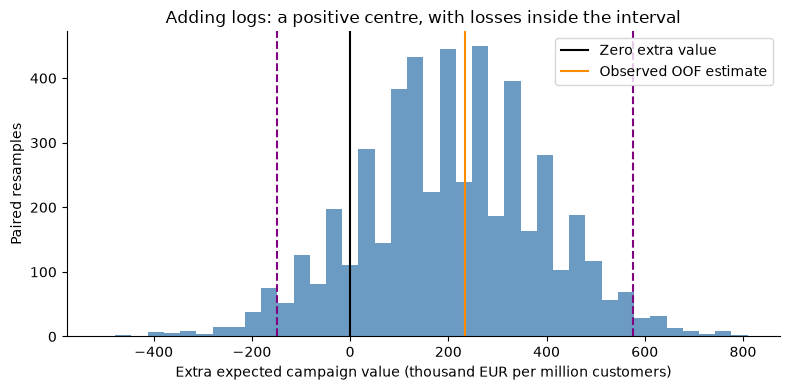

In [6]:
rng = np.random.default_rng(5262026)
bootstrap_value = np.empty(5000)
n = len(labels)
for draw in range(len(bootstrap_value)):
    ix = rng.integers(0, n, n)
    bootstrap_value[draw] = value_difference(oof["raw"][ix], oof["logs_only"][ix], labels[ix])
lo, hi = np.quantile(bootstrap_value, [0.025, 0.975])
print(f"OOF estimate per million: EUR {oof_delta:,.0f}")
print(f"Exploratory approximate 95% interval: EUR {lo:,.0f} to EUR {hi:,.0f}")
plt.hist(bootstrap_value / 1000, bins=40, color="steelblue", alpha=0.8)
plt.axvline(0, color="black", label="Zero extra value")
plt.axvline(oof_delta / 1000, color="darkorange", label="Observed OOF estimate")
for bound in (lo, hi):
    plt.axvline(bound / 1000, color="purple", linestyle="--")
plt.xlabel("Extra expected campaign value (thousand EUR per million customers)")
plt.ylabel("Paired resamples")
plt.title("Adding logs: a positive centre, with losses inside the interval")
plt.legend()
plt.tight_layout()
plt.show()

## Contrast the calculated figures with class
Values labelled **Class reference** below are comparison targets, not calculation inputs. Compare unrounded figures before presenting rounded euros. The hash confirms byte-for-byte dataset identity. OOF row order and stable sorting matter for reproducibility.

In [7]:
check = pd.DataFrame({"Calculated EUR / million": [train_delta, oof_delta, lo, hi],
                      "Class reference EUR / million": [127795.52715654952, 234291.79978700745,
                                                        -149627.26304579322, 575079.8722044729]},
                     index=["Training proxy", "OOF estimate", "Bootstrap 2.5%", "Bootstrap 97.5%"])
check["Difference from class"] = check.iloc[:, 0] - check.iloc[:, 1]
display(check.round(6))
# Investigate mismatches rather than substituting reference values.
assert np.allclose(check.iloc[:, 0], check.iloc[:, 1], rtol=0, atol=0.01), "Investigate environment/protocol discrepancy."
print("Calculated results reproduce class to within one cent per million.")

,Calculated EUR / million,Class reference EUR / million,Difference from class
Training proxy,127795.527157,127795.527157,0.0
OOF estimate,234291.799787,234291.799787,0.0
Bootstrap 2.5%,-149627.263046,-149627.263046,0.0
Bootstrap 97.5%,575079.872204,575079.872204,0.0


Calculated results reproduce class to within one cent per million.


## What does the interval cover?
This is an **exploratory, conditional percentile interval** from fixed development OOF predictions. It explores evaluation-customer composition while rebuilding both contact policies. It does not capture full uncertainty from selecting representations, retraining models, overlapping CV training sets, changing customer populations, or estimating costs and retention effectiveness. These feature choices have already been explored on development data. We did not run nested CV for this economic comparison; notebook 07's nested procedure addresses a different AP question.

Scaling from 5,634 customers to a million assumes comparable composition, costs, capacity and intervention effectiveness. It does not mean we observed a million independent customers. The 40% retention rate and costs are assumptions, not quantities demonstrated by this dataset. A controlled campaign would be needed to establish the causal effect of contacting customers.

The OOF central gain is approximately **+€234,292 per million**, compared with the **+€127,796** training proxy. Out-of-training evaluation need not shrink the *difference* between models. The approximate 95% interval runs from **−€149,627 to +€575,080** per million.

**The central estimate is positive, but the interval includes losses.** This is promising development evidence under stated assumptions, not a guaranteed future gain. A decision should weigh uncertainty, implementation cost and the value of campaign evidence. The final test remains closed.